In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/mnt/c/muco/mucol')
from hybrid_qp import length_qp_normal, find_largest_n_with_dividers
from class_geometry.ring_geometry.ring_geometry import RingGeometry, load_file
from generate_fodo_normal import DS_normal
from generate_fodo import plot_twiss, plot_chroma
from tracking.TrackingRCS import TrackingRCS, off_dE, on_dE
from generate_fodo_normal import save_para, save_table, save_tunes
from pathlib import Path


plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

STEP_QUAD = 1e-8
STEP_SXT = 1e-4

RF_FREQUENCY = 1.3e9

/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/numpy/_core/getlimits.py:552: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)
/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/xplt/hooks.py:31: RuntimeWarning: Failed to register formatters with pint: No module named 'pint'
  warnings.warn(f"Failed to register formatters with pint: {e}", RuntimeWarning)


In [2]:
mu = np.pi/2
n_size = 3
rcs_name = 'RCS3_gf'

input = load_file('/mnt/c/muco/code/FODO_cells_energy_spread.json')

sigma_delta = input[rcs_name]['sig_delta_N_'+f'{n_size}']
file_input = input[rcs_name]['file']
n_turn_rcs = input[rcs_name]['n_turn_rcs']

rcs = RingGeometry(file_input = file_input)
n_cell_qpN, cell_length_qpN, qp_para_qpN, r_qp_qpN = length_qp_normal(
    rcs, 
    mu=mu, 
    sigma_delta=sigma_delta, 
    slice=False
    )
l_qp_nc_qpN, k_nc_ext_qpN, gradient_nc_ext_qpN = qp_para_qpN['qp_nc']['length'], qp_para_qpN['qp_nc']['k'], qp_para_qpN['qp_nc']['gradient']
mask = gradient_nc_ext_qpN * r_qp_qpN < 1

# If we want to work with maximum number of cells
# n_cell_tot_N, nb_arc_N = find_largest_n_with_dividers(n_cell_qpN[mask])

/mnt/c/muco/mhega/rcsparameters/rcsparameters/ring_geometry/ring_geometry.py:316: UserWarning: Number of cells per arc was optimised from 17 to 14
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Limit nc on QP length: 675.1063829787233
Limit nc on dip BNC: 1091
Limit nc on dip BSC: 294
dip tot length 6724.137464095033
54.837193844828555 0.5579271955198741


In [3]:
# If we want to work with a given number of arcs
nb_arc_N = 32
n_cell_tot_N = max([nc for nc in n_cell_qpN[mask] if nc % nb_arc_N == 0], default=None)

# Resolution for given geometry
nb_cell_arc_N = int(n_cell_tot_N / nb_arc_N)
n_cell_N, cell_length_N, qp_para_N, r_qp_N = length_qp_normal(
    rcs, 
    n_cell = n_cell_tot_N, 
    mu = mu, 
    sigma_delta=sigma_delta, 
    slice = False
    )

l_nc_N, k_nc_N = qp_para_N['qp_nc']['length'], qp_para_N['qp_nc']['k']

rcs = RingGeometry(
    file_input = file_input, 
    length_short_insertion = l_nc_N, 
    nb_cell_arc = nb_cell_arc_N, 
    nb_arc = nb_arc_N
    )

dip tot length 6724.148585320216
71.72625730081796 0.9757822871493571
[224] [44.18526786] {'qp_nc': {'length': array([5.48336369]), 'k': array([0.01167402]), 'gradient': array([58.41051082])}} [0.01565496]


                                             
Optimize - start penalty: 0.3723                            
Matching: model call n. 13 penalty = 5.0359e-10              
Optimize - end penalty:  5.03595e-10                            


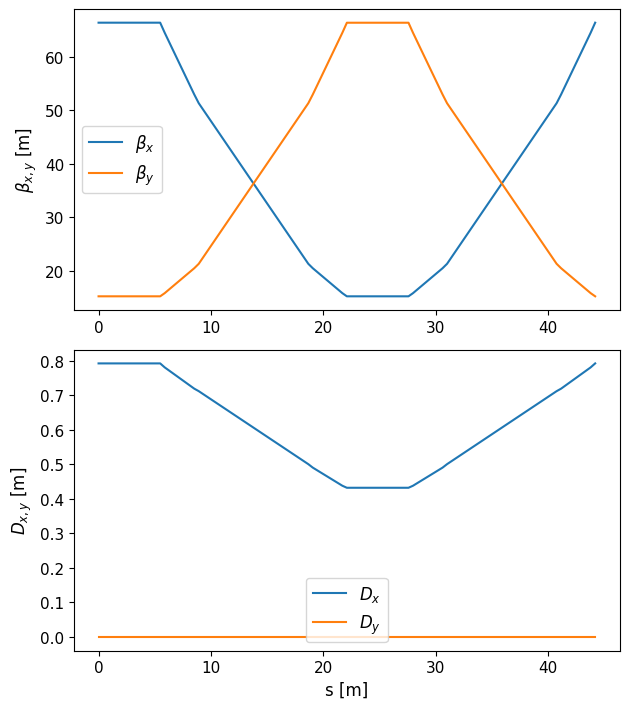

qp1 k1
qp2 k2
qp3 k3
qp4 k4
qp5 k5
                                             
Optimize - start penalty: 7.449                             
Matching: model call n. 58 penalty = 2.0154e-09              
Optimize - end penalty:  2.01542e-09                            


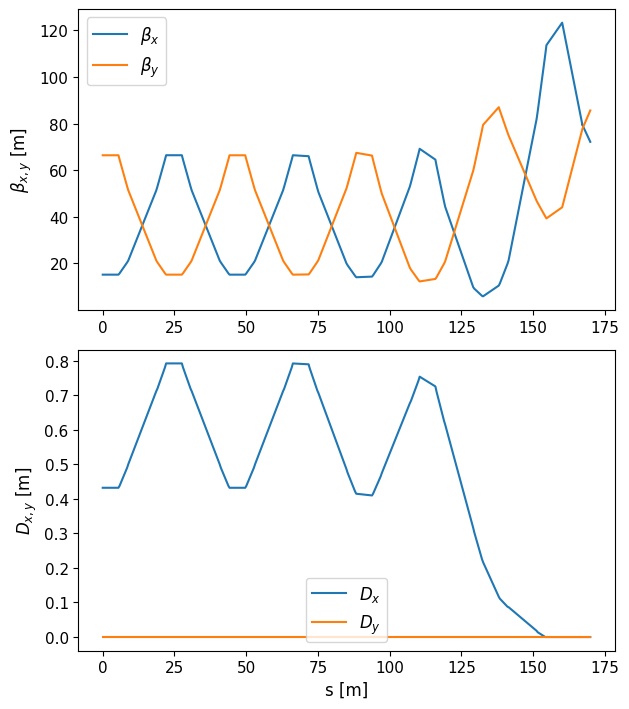

qp1 k1
qp2 k2
qp3 k3
qp4 k4
qp5 k5
                                             
Optimize - start penalty: 3.508e-08                         
Matching: model call n. 7 penalty = 1.9800e-09              
Optimize - end penalty:  1.97997e-09                            


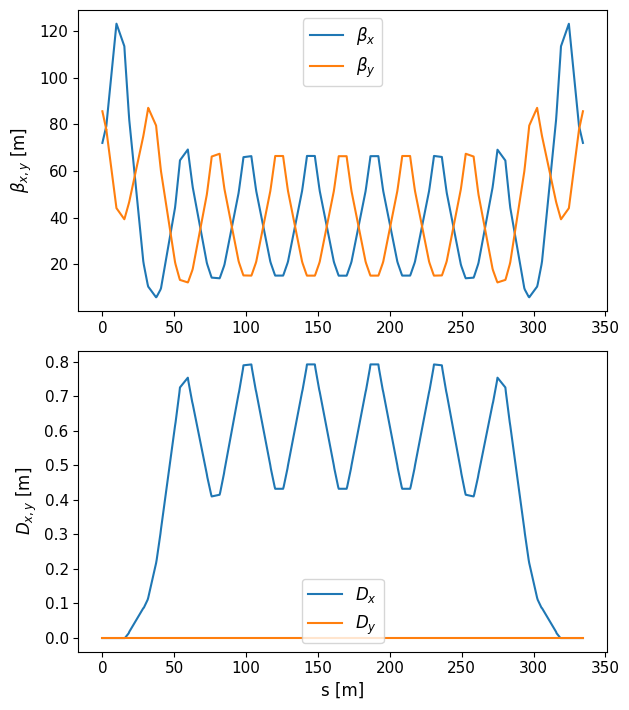

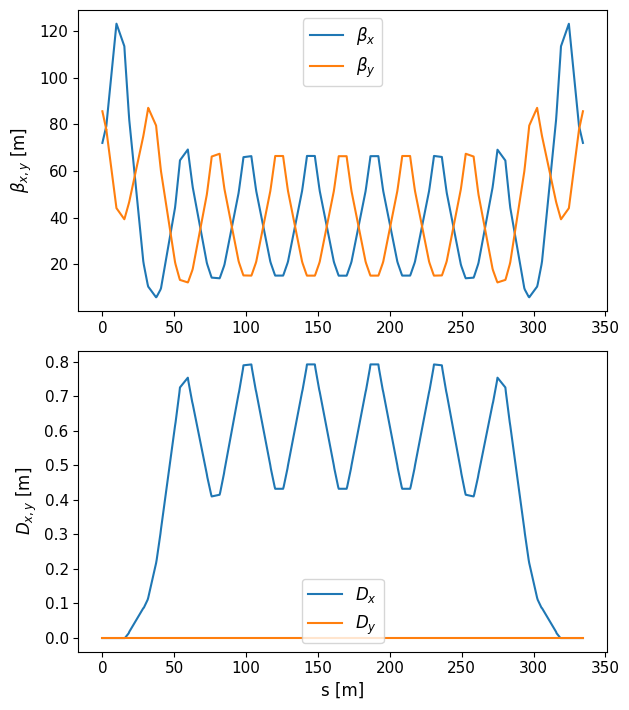

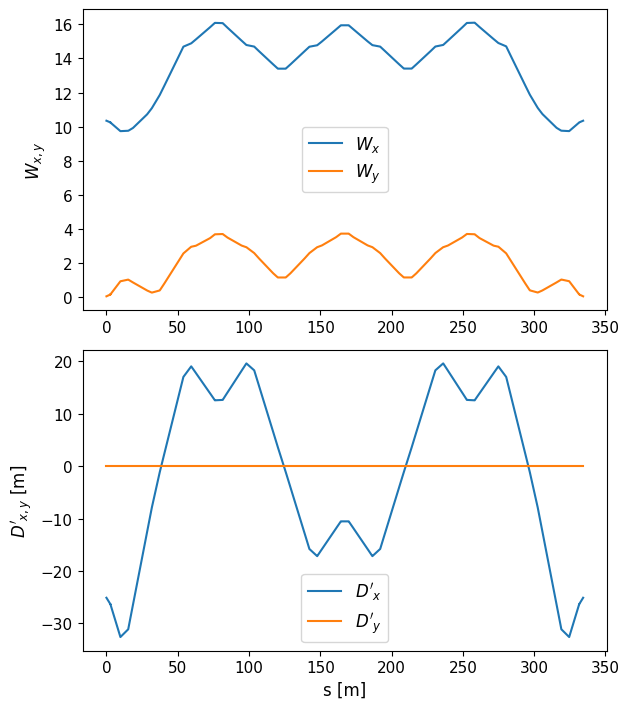

In [12]:
time_frac = 0
option = 'var_ref'

add_quad = 0
DS = DS_normal(
    rcs = rcs, 
    n_turn_rcs=n_turn_rcs, 
    time_frac=time_frac, 
    option=option, mu=mu, 
    add_quad=add_quad, 
    plot=True
    )

DS.build_arc_ds(ia = 4, knobs=[
    # 'k1', 
    'k2', 'k3', 'k4', 'k5', 
    # 'k6'
    ])
line_FODO = DS.line_FODO
line_arc = DS.line_arc
tw_arc = DS.tw_arc

fig = plot_twiss(tw_arc)
fig_chroma = plot_chroma(tw_arc)

In [ ]:
dp0c = off_dE(line_arc)
tw_arc = line_arc.twiss4d()
on_dE(line_arc, dp0c)

folder = 'lattices/lattices_final_report/' + rcs_name
save = False
if save: 
    save_para(
        rcs=rcs, 
        arc=f'_{nb_arc_N}_arc', 
        folder=folder,
        rcs_name = rcs_name
        )
    save_tunes(
        tw=tw_arc, 
        rcs=rcs, 
        arc=f'_{nb_arc_N}_arc', 
        folder=folder,
        rcs_name = rcs_name
        )

    save_table(
        rcs=rcs, 
        tw_arc=tw_arc, 
        qp_para=qp_para_N, 
        n_sigma=n_size, 
        sigma_delta=sigma_delta, 
        folder=folder,
        rcs_name = rcs_name,
        add_quad = add_quad
        )

In [ ]:
if save:
    line_arc.to_json(f'/mnt/c/muco/code/{folder}/line_{rcs_name}_normal_qp_{nb_arc_N}_arc.json')
    fig.savefig(f'/mnt/c/muco/code/{folder}/twiss_{rcs_name}_normal_qp_{nb_arc_N}_arc.png')
    fig_chroma.savefig(f'/mnt/c/muco/code/{folder}/chroma_{rcs_name}_normal_qp_{nb_arc_N}_arc.png')

In [ ]:
n_part = 5000
nemitt_x = 25e-6
nemitt_y = 25e-6
nemitt_s = 0.025

input = {
    'RCS3_gf': {
        'n_turn_rcs' : 66,
        't_acc' : 2.37e-3,
        'sigma_z' : 14e-12,
    },
}

n_turn_rcs = input[rcs_name]['n_turn_rcs']
t_acc = input[rcs_name]['t_acc']
sigma_z = input[rcs_name]['sigma_z']
nb_arc_tot = n_turn_rcs*rcs.nb_arc

----- Generating particle distribution -----
Emittance at injection, before 2nd order matching 2.5001013172616135e-05
----- Initial particle distribution and separatrix -----


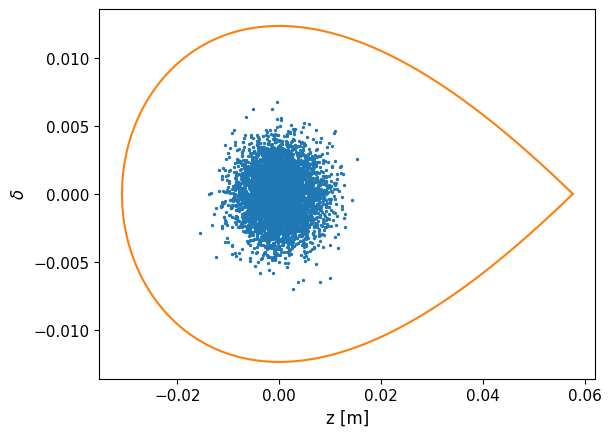

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 327360/327360 [00:01<00:00, 219871.50it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.500520946137802e-05
ey = 2.4860293908344225e-05
es = 0.021957734644139536
----- Tracking results at extraction -----
ex = 2.58341666030844e-05
ey = 2.4831587268209573e-05
es = 0.022051513864472107
tr = 0.9994
----- Growth at extraction -----
ex = 3.315137763539841
ey = -0.11547184534699538
es = 0.42708968776794903


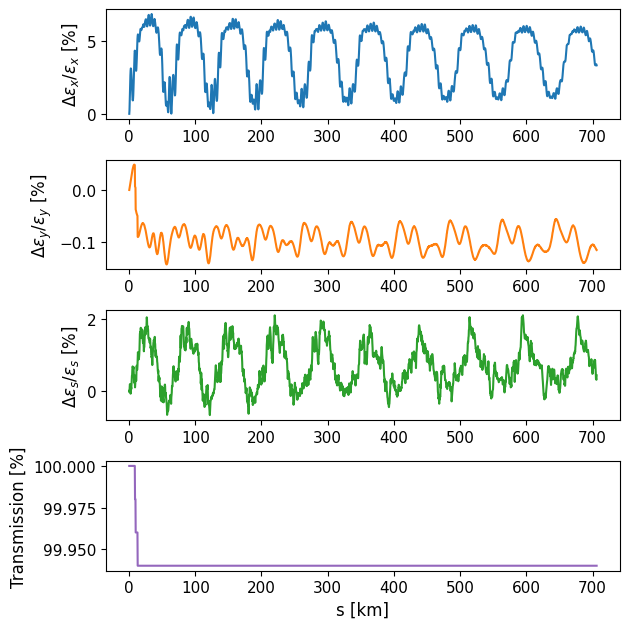

In [20]:
ramp = False
method = 'var_ref'
n_sigma = 5
RF_tuning = False
adapt_part = False
plt_twiss = False
plt_sepa = True

tracking = False
if tracking:
    track_rcs = TrackingRCS(
        line = line_arc,
        rcs =rcs,
        n_turn_rcs = n_turn_rcs,
        n_part=n_part,
        nemitt_x=nemitt_x,
        nemitt_y=nemitt_y,
        sigma_z=sigma_z,
        t_acc = t_acc,
        ramp = ramp,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        adapt_part = adapt_part,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
    )